# 04 · Random Forest: severidad al momento de la admisión

**Caso hipotético:** Hospital San Juan de Dios de Rionegro. **Beneficiarios:** directiva médica, coordinación de urgencias y gestión operativa.

> Al momento de la admisión de un paciente, ¿con qué desempeño puede un modelo predecir su nivel de gravedad (`Severity of Illness`: Minor, Moderate, Extreme) a partir de información demográfica, antecedentes de salud, tipo de ingreso y variables logísticas disponibles, para apoyar el triaje preliminar y la planificación anticipada de camas y personal?

**Decisiones que apoya (de forma preliminar):** planificación de camas, distribución preventiva de personal, anticipación de picos de severidad alta y priorización operativa inicial en urgencias.

⚠️ El modelo **no** toma decisiones clínicas ni reemplaza la valoración médica: es un apoyo administrativo sujeto a validación clínica, revisión de sesgos y supervisión humana.

**Tipo de aprendizaje:** supervisado, clasificación multiclase. **Algoritmo:** `RandomForestClassifier`, `random_state=42`, división 80/20 estratificada.

## 1. Preparar el entorno e importar la lógica desde `src`

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))  # permite `import src...` sin rutas absolutas

import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

from src import config
from src.data.dataset_io import build_metadata, build_preprocessing_evidence, download_and_clean
from src.models.train_random_forest import (
    CANDIDATE_CONFIGS, EXCLUDED_COLUMNS, FEATURES, TARGET, export_model, train_random_forest,
)
from src.utils.reporter import RandomForestReporter

/opt/hostedtoolcache/Python/3.12.16/x64/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Carga automática del dataset y estructura inicial
`download_and_clean()` usa `HFDatasetLoader` (descarga el dataset completo desde Hugging Face) y aplica el preprocesamiento reutilizable de `src/data/preprocessing.py`. Dataset: [`Nicolybgs/healthcare_data`](https://huggingface.co/datasets/Nicolybgs/healthcare_data), split `train`.

In [2]:
raw, processed, info = download_and_clean()
metadata = build_metadata(info, raw, processed)
evidence = build_preprocessing_evidence(raw, processed, FEATURES)
print(f"Dataset: {metadata['dataset_id']} | config={metadata['config']} | split={metadata['split']}")
print(f"Tamaño original: {raw.shape[0]:,} filas x {raw.shape[1]} columnas")
display(raw.dtypes.rename("tipo").to_frame().T)
raw.head()

Dataset: Nicolybgs/healthcare_data | config=default | split=train
Tamaño original: 500,000 filas x 15 columnas


,Available Extra Rooms in Hospital,Department,Ward_Facility_Code,doctor_name,staff_available,patientid,Age,gender,Type of Admission,Severity of Illness,health_conditions,Visitors with Patient,Insurance,Admission_Deposit,Stay (in days)
tipo,int64,object,object,object,int64,int64,object,object,object,object,object,int64,object,float64,int64


,Available Extra Rooms in Hospital,Department,Ward_Facility_Code,doctor_name,staff_available,patientid,Age,gender,Type of Admission,Severity of Illness,health_conditions,Visitors with Patient,Insurance,Admission_Deposit,Stay (in days)
0,4,gynecology,D,Dr Sophia,0,33070,41-50,Female,Trauma,Extreme,Diabetes,4,Yes,2966.408696,8
1,4,gynecology,B,Dr Sophia,2,34808,31-40,Female,Trauma,Minor,Heart disease,2,No,3554.835677,9
2,2,gynecology,B,Dr Sophia,8,44577,21-30,Female,Trauma,Extreme,Diabetes,2,Yes,5624.733654,7
3,4,gynecology,D,Dr Olivia,7,3695,31-40,Female,Urgent,Moderate,None,4,No,4814.149231,8
4,2,anesthesia,E,Dr Mark,10,108956,71-80,Male,Trauma,Moderate,Diabetes,2,No,5169.269637,34


## 3. Estado antes y después del preprocesamiento
Transformaciones: nombres a `snake_case`, `Age` → `age_midpoint` (punto medio del rango), nulos de `health_conditions` → categoría `"None"`, duplicados eliminados **antes** de quitar `patientid`, y eliminación del identificador. La imputación y la codificación de las variables predictoras se ajustan **solo con el entrenamiento**, dentro del `Pipeline`.

In [3]:
display(evidence)
processed.head()

,metrica,antes,despues
0,filas,500000,500000
1,columnas,15,14
2,filas duplicadas,0,0
3,valores nulos (total),151888,0
4,columnas de texto (object),9,8
5,columnas numéricas,6,6
6,columnas eliminadas,,"Admission_Deposit, Age, Available Extra Rooms ..."
7,columnas creadas/renombradas,,"admission_deposit, age_midpoint, available_ext..."
8,nulos en health_conditions,151888,
9,variables predictoras finales,,"age_midpoint, visitors_with_patient, staff_ava..."


,available_extra_rooms_in_hospital,department,ward_facility_code,doctor_name,staff_available,gender,type_of_admission,severity_of_illness,health_conditions,visitors_with_patient,insurance,admission_deposit,stay_in_days,age_midpoint
0,4,gynecology,D,Dr Sophia,0,Female,Trauma,Extreme,Diabetes,4,Yes,2966.408696,8,45.5
1,4,gynecology,B,Dr Sophia,2,Female,Trauma,Minor,Heart disease,2,No,3554.835677,9,35.5
2,2,gynecology,B,Dr Sophia,8,Female,Trauma,Extreme,Diabetes,2,Yes,5624.733654,7,25.5
3,4,gynecology,D,Dr Olivia,7,Female,Urgent,Moderate,None,4,No,4814.149231,8,35.5
4,2,anesthesia,E,Dr Mark,10,Male,Trauma,Moderate,Diabetes,2,No,5169.269637,34,75.5


## 4. Variables excluidas para prevenir fuga de información
Solo se usan variables conocidas **al momento de la admisión**. Se excluyen las que se conocen después de la atención o que podrían revelar la gravedad:

In [4]:
display(pd.Series(EXCLUDED_COLUMNS, name="motivo de exclusión").to_frame())
print("Variables predictoras:", FEATURES)
display(processed[TARGET].value_counts(normalize=True).rename("proporción").to_frame())

,motivo de exclusión
severity_of_illness,Es la variable objetivo.
stay_in_days,Se conoce después de la atención; usarla sería...
admission_deposit,Se calcula/cobra durante o después de la admis...
department,Se asigna tras el triaje y puede revelar indir...
ward_facility_code,Se asigna después de valorar al paciente; pued...
doctor_name,Depende de la asignación posterior al triaje; ...
patientid,Identificador sin valor predictivo (ya elimina...


Variables predictoras: ['age_midpoint', 'visitors_with_patient', 'staff_available', 'available_extra_rooms_in_hospital', 'gender', 'health_conditions', 'type_of_admission', 'insurance']


,proporción
severity_of_illness,
Moderate,0.560394
Minor,0.263074
Extreme,0.176532


**Distribución de clases:** `Moderate` domina y `Extreme` es la clase minoritaria pero la más costosa de omitir. Por eso la comparación de hiperparámetros incluye `class_weight=None` y `class_weight="balanced_subsample"`, y el criterio de selección considera el *recall* de `Extreme`.

## 5. ¿Cómo funciona un Random Forest?
1. Se toman muchas muestras aleatorias (con reemplazo) de los pacientes de entrenamiento.
2. Con cada muestra se construye un árbol de decisión; en cada división el árbol solo mira un subconjunto aleatorio de variables, lo que hace que los árboles sean distintos entre sí.
3. Para un paciente nuevo, cada árbol «vota» una severidad y gana la clase más votada.
4. Promediar muchos árboles reduce el sobreajuste de un árbol individual.

Parámetros principales: `n_estimators` (número de árboles), `max_depth` (profundidad máxima), `min_samples_leaf` (mínimo de pacientes por hoja; hojas grandes = modelo más simple) y `class_weight` (da más peso a las clases minoritarias). **No se escalan las variables:** los árboles dividen por umbrales, así que la escala no cambia el resultado.

## 6. Comparación de configuraciones, selección y entrenamiento final
Se comparan las configuraciones candidatas en una **submuestra estratificada del entrenamiento** (100 000 filas; 75 % ajuste / 25 % validación) para controlar el tiempo en GitHub Actions. **Criterio:** entre las configuraciones con F1 ponderado a menos de 0.01 del mejor y cuyo modelo exportado estimado no supere el límite de tamaño (los modelos con hojas muy pequeñas pesan cientos de MB con el dataset completo y no caben en GitHub), se elige la de mayor *recall* de `Extreme`. **El modelo final se entrena con todo el 80 % de entrenamiento (400 000 filas)** y se evalúa en el 20 % de prueba, independiente.

In [5]:
display(pd.DataFrame(CANDIDATE_CONFIGS))
run = train_random_forest(processed)
res = run.results
display(run.hyperparameter_comparison)
print(res["selection_rationale"])
print("Hiperparámetros seleccionados:", res["hyperparameters_selected"])
print("Tiempos (s):", {k: round(v, 1) for k, v in res["timing_seconds"].items()})
print("Train/test:", res["split"])

,name,n_estimators,max_depth,min_samples_leaf,class_weight
0,RF-1,100,15.0,100,None
1,RF-2,100,15.0,100,balanced_subsample
2,RF-3,200,15.0,100,balanced_subsample
3,RF-4,200,15.0,200,balanced_subsample
4,RF-5,200,25.0,50,balanced_subsample
5,RF-6,100,15.0,5,None
6,RF-7,100,NaN,1,None


,config,n_estimators,max_depth,min_samples_leaf,class_weight,accuracy,f1_weighted,recall_extreme,fit_seconds,est_final_model_mb
0,RF-1,100,15,100,None,0.5811,0.4763,0.2855,1.1842,10.2180
1,RF-2,100,15,100,balanced_subsample,0.4750,0.4847,0.5905,1.3111,11.8892
2,RF-3,200,15,100,balanced_subsample,0.4765,0.4861,0.5894,2.3548,23.6330
3,RF-4,200,15,200,balanced_subsample,0.4740,0.4836,0.5880,2.2478,12.5067
4,RF-5,200,25,50,balanced_subsample,0.4805,0.4903,0.5776,2.6065,45.8416
5,RF-6,100,15,5,None,0.5837,0.5033,0.2860,1.4281,60.6228
6,RF-7,100,None,1,None,0.5241,0.4973,0.2860,2.1060,292.8797


Se eligió RF-2: entre las configuraciones con F1 ponderado a menos de 0.01 del mejor (0.4861) y modelo exportado estimado <= 40 MB, es la de mayor recall de la clase Extreme (0.5905). Tiempo de ajuste en la submuestra: 1.3 s.
Hiperparámetros seleccionados: {'n_estimators': 100, 'max_depth': 15, 'min_samples_leaf': 100, 'class_weight': 'balanced_subsample', 'config': 'RF-2', 'random_state': 42, 'n_jobs': -1}
Tiempos (s): {'hyperparameter_search': 13.2, 'final_training': 10.2}
Train/test: {'test_size': 0.2, 'random_state': 42, 'stratified': True, 'n_rows_modeling': 500000, 'n_train_available': 400000, 'n_train_used': 400000, 'n_test': 100000, 'train_sampling': 'entrenamiento con el 100 % de la partición de entrenamiento', 'search_rows': 100000}


## 7. Métricas en el conjunto de prueba y comparación con la línea base

In [6]:
display(pd.Series(res["metrics"], name="valor").to_frame())
display(run.metrics_by_class.round(4))
print(f"Recall de Extreme: {res['recall_extreme']:.4f}")
display(pd.DataFrame({"modelo": {"accuracy": res["metrics"]["accuracy"], "f1_weighted": res["metrics"]["f1_weighted"], "recall_extreme": res["recall_extreme"]},
                      "línea base (siempre " + res["baseline"]["majority_class"] + ")": {"accuracy": res["baseline"]["accuracy"], "f1_weighted": res["baseline"]["f1_weighted"], "recall_extreme": res["baseline"]["recall_extreme"]}}))

,valor
accuracy,0.481130
precision_weighted,0.537136
recall_weighted,0.481130
f1_weighted,0.491320


,class,precision,recall,f1,support
0,Minor,0.3660,0.4397,0.3995,26307.0
1,Moderate,0.6748,0.4617,0.5483,56040.0
2,Extreme,0.3551,0.6047,0.4475,17653.0


Recall de Extreme: 0.6047


,modelo,línea base (siempre Moderate)
accuracy,0.481130,0.560400
f1_weighted,0.491320,0.402523
recall_extreme,0.604713,0.000000


## 8. Exportar el modelo y generar reportes y gráficas automáticamente

In [7]:
export_model(run)                                   # models/random_forest_severity.pkl
paths = RandomForestReporter(run, metadata, evidence).save_all()
for name, path in paths.items():
    print(f"{name:20s} {Path(path).relative_to(ROOT).as_posix()}")
print("Modelo:", res["model_path"], f"({res['model_size_mb']} MB)")

confusion_matrix     reports/random_forest/figures/confusion_matrix.png
feature_importance   reports/random_forest/figures/feature_importance.png
hyperparameters      reports/random_forest/hyperparameter_comparison.csv
metrics_by_class     reports/random_forest/metrics_by_class.csv
results_json         reports/random_forest/results.json
summary_txt          reports/random_forest/model-summary.txt
findings_md          reports/random_forest/findings.md
Modelo: models/random_forest_severity.pkl (8.45 MB)


### 8.1 Matriz de confusión

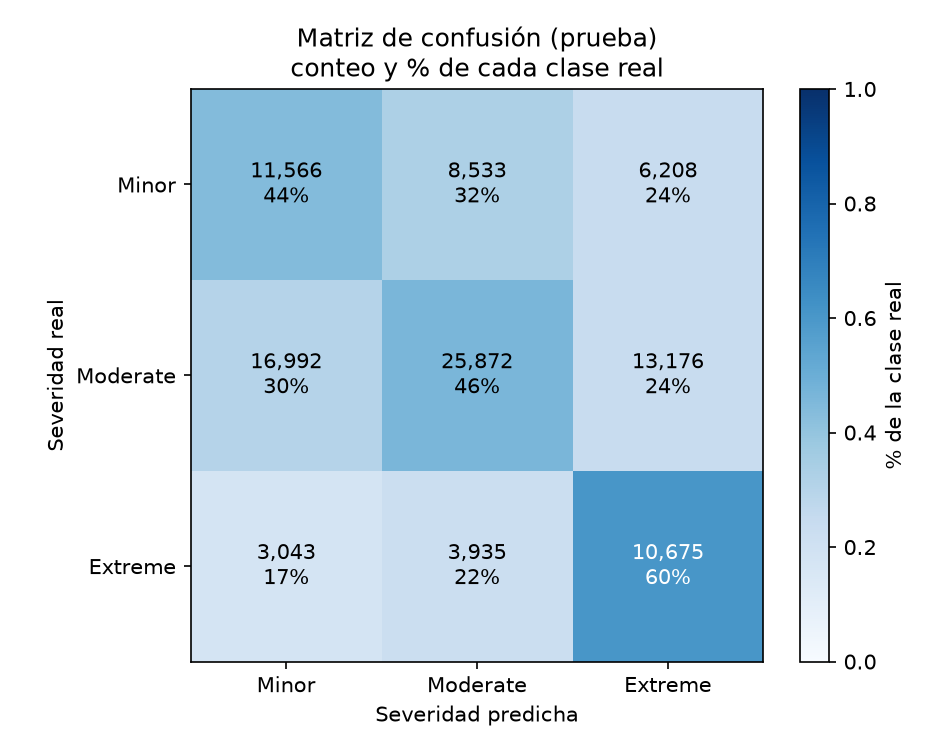

In [8]:
Image(filename=str(config.RF_CONFUSION_PNG))

Las filas son la severidad real y las columnas la predicha. Se observa cuántos pacientes `Extreme` el modelo clasifica como `Minor` o `Moderate` (casos omitidos) y cuántos de los clasificados como `Extreme` no lo son (falsas alarmas).

### 8.2 Importancia de variables (permutación en prueba + importancia interna agrupada)

,feature,importance_mean,importance_std
0,health_conditions,0.07412,0.00119
1,type_of_admission,0.03447,0.00132
2,visitors_with_patient,0.02745,0.00034
3,available_extra_rooms_in_hospital,0.01715,0.00080
4,age_midpoint,0.00493,0.00050
5,gender,0.00447,0.00031
6,staff_available,0.00028,0.00022
7,insurance,0.00027,0.00027


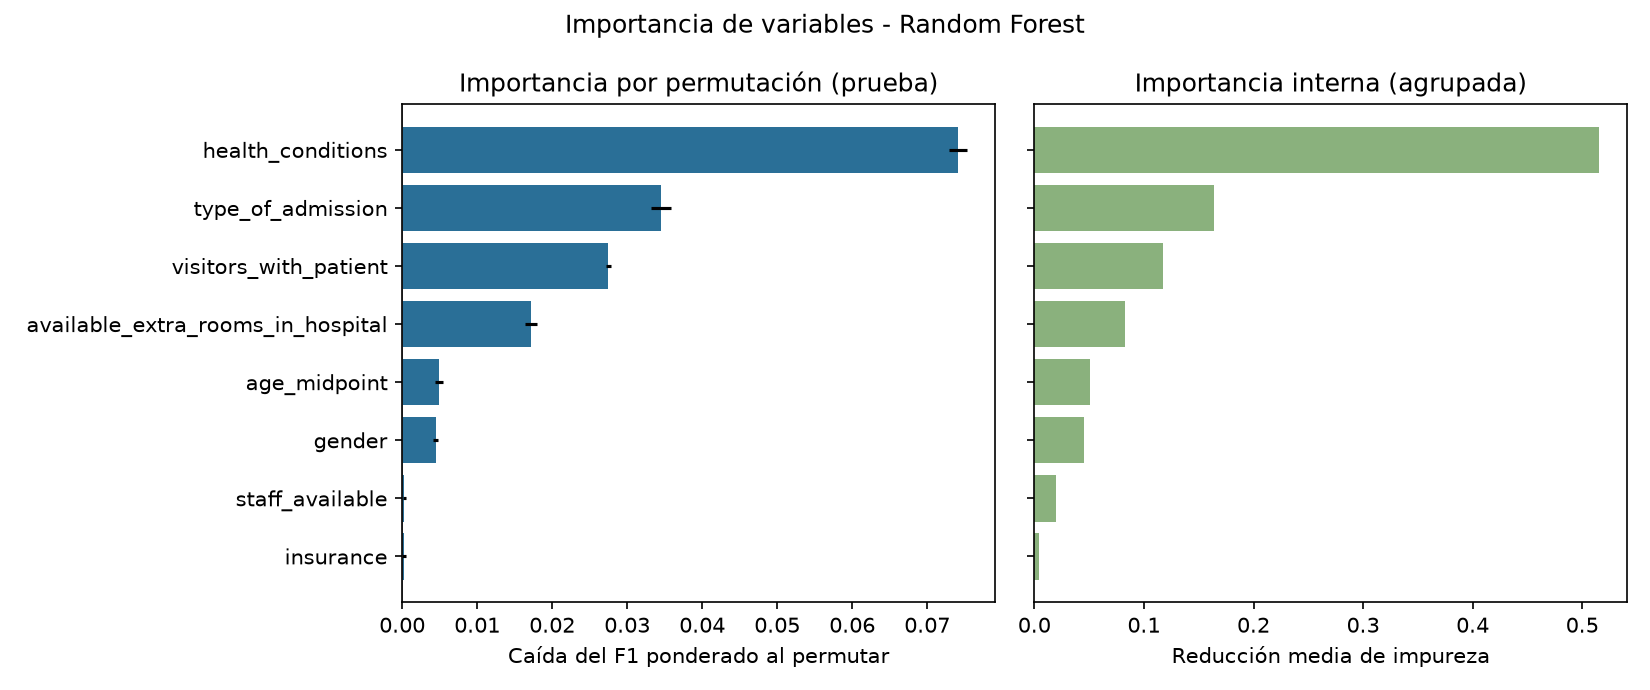

In [9]:
display(run.permutation_importance.round(5))
Image(filename=str(config.RF_IMPORTANCE_PNG))

La **importancia por permutación** mide cuánto cae el F1 ponderado al desordenar una variable en el conjunto de prueba; es menos engañosa que la importancia interna, que favorece variables con muchas categorías. Las columnas One-Hot de una misma variable se agrupan en la variable original.

## 9. Respuesta a la pregunta de negocio

In [10]:
reporter = RandomForestReporter(run, metadata, evidence)
display(Markdown("**Valoración de utilidad operativa:** " + res["utility_assessment"]["level"]))
display(Markdown("**Criterio:** " + res["utility_assessment"]["criteria"]))
display(Markdown("\n".join("- " + t for t in reporter.interpretation())))
display(Markdown("### Limitaciones\n" + "\n".join("- " + t for t in reporter.limitations())))

**Valoración de utilidad operativa:** utilidad limitada

**Criterio:** Apto si el F1 ponderado supera a la línea base en >= 0.15 y el recall de Extreme es >= 0.6; limitado si el aumento de F1 es >= 0.05; en otro caso, sin valor operativo. Es un criterio interno del proyecto, no un estándar clínico.

- Clase mejor identificada: Extreme (recall=0.605); peor identificada: Minor (recall=0.440).
- De 17653 pacientes Extreme reales en prueba, el modelo acertó 10675 (60.5%) y confundió 3043 como Minor, 3935 como Moderate.
- Frente a la línea base: accuracy 0.4811 vs 0.5604 y F1 ponderado 0.4913 vs 0.4025.
- Valoración de utilidad operativa: utilidad limitada. Criterio: Apto si el F1 ponderado supera a la línea base en >= 0.15 y el recall de Extreme es >= 0.6; limitado si el aumento de F1 es >= 0.05; en otro caso, sin valor operativo. Es un criterio interno del proyecto, no un estándar clínico.
- La variable con mayor importancia por permutación es health_conditions (0.07412); 6 de 8 variables tienen un aporte claramente distinguible del ruido (media > 2 desviaciones).

### Limitaciones
- Las variables disponibles al ingreso tienen poder discriminante limitado; el desempeño medido no debe extrapolarse a otros hospitales o periodos sin validación local.
- El dataset es público y de origen no verificado; podría no representar a la población del hospital.
- Se asume que visitors_with_patient, staff_available y available_extra_rooms_in_hospital se conocen en el momento de la admisión; si no, habría que retirarlas.
- La búsqueda de hiperparámetros se hizo en una submuestra estratificada de 100,000 filas por tiempo de cómputo; el modelo final usa todo el entrenamiento.
- Los modelos con hojas pequeñas (más pesados) se excluyeron de la selección para que el modelo exportado pese menos de lo permitido por GitHub.
- No se evaluó equidad por género, edad o seguro; antes de cualquier uso real se requiere auditoría de sesgos.
- Las importancias por permutación son asociaciones predictivas, no causas clínicas.
- No debe usarse como diagnóstico ni para decidir tratamiento: es solo apoyo administrativo preliminar.

**Conclusión:** la respuesta cuantitativa está en las métricas y en la valoración anterior, generadas desde esta ejecución. Debe leerse junto con las limitaciones: es un apoyo administrativo preliminar, **no** un diagnóstico, y requiere validación clínica, auditoría de sesgos y supervisión humana antes de cualquier uso real.

## 10. Reportes automáticos generados

In [11]:
print("Resumen técnico :", config.RF_SUMMARY_TXT.relative_to(ROOT).as_posix())
print("Hallazgos (md)  :", config.RF_FINDINGS_MD.relative_to(ROOT).as_posix())
print()
print("\n".join(config.RF_SUMMARY_TXT.read_text(encoding="utf-8").splitlines()[:30]))

Resumen técnico : reports/random_forest/model-summary.txt
Hallazgos (md)  : reports/random_forest/findings.md

RESUMEN AUTOMÁTICO - RANDOM FOREST
Fecha y hora de ejecución: 2026-11-09 02:06:56 UTC+0000
Institución / caso: Hospital San Juan de Dios de Rionegro (caso hipotético)

1. PREGUNTA DE NEGOCIO
------------------------------------------------------------------------
Al momento de la admisión de un paciente, ¿con qué desempeño puede un modelo predecir su nivel de gravedad (Severity of Illness: Minor, Moderate, Extreme) a partir de información demográfica, antecedentes de salud, tipo de ingreso y variables logísticas disponibles, para apoyar el triaje preliminar y la planificación anticipada de camas y personal?

2. DATASET
------------------------------------------------------------------------
Identificador: Nicolybgs/healthcare_data
URL: https://huggingface.co/datasets/Nicolybgs/healthcare_data
Configuración / split: default / train
Tamaño del DataFrame original: 500000 x 15
Tam

In [12]:
display(Markdown(config.RF_FINDINGS_MD.read_text(encoding="utf-8").replace("figures/", "../reports/random_forest/figures/")))

# Hallazgos: predicción de severidad con Random Forest

_Hospital San Juan de Dios de Rionegro (caso hipotético) · Generado automáticamente el 2026-11-09 02:06_

## 1. Pregunta de negocio

> Al momento de la admisión de un paciente, ¿con qué desempeño puede un modelo predecir su nivel de gravedad (Severity of Illness: Minor, Moderate, Extreme) a partir de información demográfica, antecedentes de salud, tipo de ingreso y variables logísticas disponibles, para apoyar el triaje preliminar y la planificación anticipada de camas y personal?

## 2. Respuesta

El modelo **mejora de forma modesta** a una regla trivial; sirve, como mucho, como una señal complementaria débil. Con los datos de admisión disponibles, el modelo acierta la severidad en **48.1%** de los pacientes de prueba; una regla que siempre dijera «Moderate» acertaría **56.0%**. Al ponderar por clase (F1), el modelo obtiene **0.491** frente a **0.403** de la regla trivial (diferencia +0.089). Valoración según el criterio interno del proyecto: **utilidad limitada**.

## 3. Hallazgos principales

- Se evaluó en 100,000 pacientes de prueba que el modelo no vio al entrenar.
- Clase mejor identificada: **Extreme** (recall 60.5%); la más difícil: **Minor** (recall 44.0%).
- De 17,653 pacientes realmente **Extreme**, el modelo detectó 10,675 (60.5%) y no detectó 6,978 (3,043 como Minor; 3,935 como Moderate).
- Variables con mayor aporte (importancia por permutación): health_conditions (0.0741), type_of_admission (0.0345), visitors_with_patient (0.0274).

## 4. Cómo leer las gráficas

![Matriz de confusión](../reports/random_forest/figures/confusion_matrix.png)

Cada fila es la severidad real y cada columna la que predijo el modelo. La diagonal son los aciertos; fuera de ella están los errores. El porcentaje indica qué parte de cada clase real cayó en cada predicción.

![Importancia de variables](../reports/random_forest/figures/feature_importance.png)

Izquierda: cuánto empeora el modelo si se «desordena» una variable (cuanto más baja el F1, más la usa el modelo). Derecha: importancia interna del bosque, agrupando las categorías de una misma variable. Valores cercanos a cero indican que la variable casi no ayuda a predecir.

## 5. Confiabilidad del resultado

- División 80/20 estratificada con semilla fija (42); resultados reproducibles.
- Entrenamiento con 400,000 filas (entrenamiento con el 100 % de la partición de entrenamiento).
- Configuración elegida comparando 7 alternativas (RF-2); criterio: F1 ponderado y recall de Extreme.
- Una sola partición de prueba: no se midió la variabilidad entre particiones.

## 6. Errores y limitaciones

- Las variables disponibles al ingreso tienen poder discriminante limitado; el desempeño medido no debe extrapolarse a otros hospitales o periodos sin validación local.
- El dataset es público y de origen no verificado; podría no representar a la población del hospital.
- Se asume que visitors_with_patient, staff_available y available_extra_rooms_in_hospital se conocen en el momento de la admisión; si no, habría que retirarlas.
- La búsqueda de hiperparámetros se hizo en una submuestra estratificada de 100,000 filas por tiempo de cómputo; el modelo final usa todo el entrenamiento.
- Los modelos con hojas pequeñas (más pesados) se excluyeron de la selección para que el modelo exportado pese menos de lo permitido por GitHub.
- No se evaluó equidad por género, edad o seguro; antes de cualquier uso real se requiere auditoría de sesgos.
- Las importancias por permutación son asociaciones predictivas, no causas clínicas.
- No debe usarse como diagnóstico ni para decidir tratamiento: es solo apoyo administrativo preliminar.

## 7. Recomendaciones operativas

- **No** usar este modelo para planificar camas ni personal con la información actual.
- Mantener el triaje manual: el modelo omitiría 6,978 de 17,653 pacientes Extreme.
- Evaluar variables adicionales disponibles al ingreso (signos vitales, motivo de consulta, escala de triaje) antes de repetir el estudio.
- Validar con datos propios del hospital y auditar sesgos (género, edad, seguro) antes de cualquier piloto.
- Repetir la evaluación periódicamente para detectar deterioro del desempeño.

## 8. Advertencia

**Este modelo es un apoyo administrativo y preliminar. NO es un diagnóstico ni una decisión clínica autónoma: requiere validación clínica, revisión de sesgos y supervisión humana.**
